# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

In [ ]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [ ]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [ ]:
FAST_MODE = True   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = set()        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [ ]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [ ]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    
    sh, sw = pair(stride)
    dh, dw = pair(dilation)
    ph, pw = pair(padding)

    if ph > 0 or pw > 0:
        x_pad = F.pad(x, (pw, pw, ph, ph))
    else:
        x_pad = x

    H_out = conv_output_size(H, kh, sh, ph, dh)
    W_out = conv_output_size(W, kw, sw, pw, dw)
    L = H_out * W_out

    cols = F.unfold(x_pad, kernel_size=(kh, kw), dilation=(dh, dw), stride=(sh, sw))
    cols = cols.view(B, groups, _ * kh * kw, L)
    w = weight.view(groups, C_out // groups, _ * kh * kw)
    out = torch.matmul(w.unsqueeze(0), cols)

    out = out.view(B, C_out, H_out, W_out)
    if bias is not None:
        out = out + bias.view(1, C_out, 1, 1)

    return out

In [ ]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [ ]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.**

1.  При `padding = k // 2` пространственные размеры выхода совпадают с размерами входа ($H_{out} \approx H, W_{out} \approx W$). Тензор `cols` имеет форму $(B, C_{in} \cdot k^2, H \cdot W)$, тогда как исходный вход $x$ — $(B, C_{in}, H, W)$. Отношение числа элементов равно ровно $k^2$. Для $k = 3, 5, 7$ это увеличение памяти в $9\times$, $25\times$ и $49\times$ соответственно (что подтверждается выводом).

2.  Поскольку затраты памяти и времени на im2col растут квадратично от размера ядра ($O(k^2)$), при больших $k$ (обычно $k \ge 7$ или $11$) этот метод становится неэффективным. В этот момент FFT-свёртка начинает выигрывать, так как её вычислительная сложность зависит от размера карты признаков как $O(H W \log(H W))$ и почти не зависит от размера ядра $k$.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [ ]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding

        B, C_in, H, W = x.shape
        C_out, _, k, _ = weight.shape
        H_out, W_out = grad_out.shape[2], grad_out.shape[3]

        x_unfold = F.unfold(x, kernel_size=k, stride=s, padding=p)
        grad_out_flat = grad_out.view(B, C_out, -1)
        grad_w = torch.matmul(grad_out_flat, x_unfold.transpose(1, 2)).sum(dim=0)
        grad_w = grad_w.view(C_out, C_in, k, k)

        op_h = H - ((H_out - 1) * s - 2 * p + k)
        op_w = W - ((W_out - 1) * s - 2 * p + k)
        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))

        grad_b = grad_out.sum(dim=(0, 2, 3)) if ctx.needs_input_grad[2] else None

        return grad_x, grad_w, grad_b, None, None

In [ ]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Для свёртки $3 \times 3$ со stride $s=2$ и padding $p=1$:

1. При $H = 3$: $H_{out} = \lfloor(3 + 2\cdot1 - 3)/2\rfloor + 1 = 2$. Формула даёт $op = 3 - ((2 - 1)\cdot2 - 2\cdot1 + 3) = 3 - 3 = 0$.

2. При $H = 4$: $H_{out} = \lfloor(4 + 2\cdot1 - 3)/2\rfloor + 1 = 2$. Формула даёт $op = 4 - ((2 - 1)\cdot2 - 2\cdot1 + 3) = 4 - 3 = 1$.

Таким образом, размеры $H=3$ и $H=4$ дают одинаковый $H_{out}=2$, но требуют разного `output_padding` (0 и 1 соответственно) для корректного восстановления исходной размерности при обратном проходе.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [ ]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)

    out = model(x)

    h_center = out.shape[2] // 2
    w_center = out.shape[3] // 2

    target = out[0, :, h_center, w_center].sum()

    grad = torch.autograd.grad(target, x)[0]
    grad_abs = grad.abs().sum(dim=(0, 1))
    rows, cols = torch.where(grad_abs > 1e-8)

    if len(rows) == 0:
        return (0, 0)

    h_box = (rows.max() - rows.min() + 1).item()
    w_box = (cols.max() - cols.min() + 1).item()

    return (h_box, w_box)


In [ ]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Усредняющие ядра без нелинейностей взяты потому, что все их веса строго положительны ($1/k^2$). Это гарантирует, что градиент от центрального пикселя выхода распространится на все пиксели входа в теоретическом receptive field, и эмпирический RF в точности совпадет с теоретическим. Эксперимент подтверждает это: для всех архитектур (включая dilated и strided) `empirical_rf` совпадает с теоретическим значением.

С `MaxPool` ситуация меняется качественно: градиент проходит только через один пиксель (максимальный) в каждом окне пулинга. Из-за этого эмпирический RF становится "прореженным" — ненулевые пиксели образуют разреженный паттерн, а не сплошной bounding box. Однако размер bounding box (максимальное расстояние между ненулевыми пикселями) остается таким же, как теоретический RF, потому что максимальный пиксель может находиться на любой позиции окна. В наших тестах `MaxPool instead of AvgPool` дал те же значения (9, 18, 17, 15), что подтверждает: bounding box не меняется, но распределение градиента внутри него становится неравномерным и зависит от конкретного входа.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [ ]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    total_grad = torch.zeros(size, size)

    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)
        out = model(x)

        h_center = out.shape[2] // 2
        w_center = out.shape[3] // 2
        target = out[0, :, h_center, w_center].sum()

        grad = torch.autograd.grad(target, x)[0]
        total_grad += grad.abs().sum(dim=(0, 1))

    prob_map = total_grad / total_grad.sum()

    row_marginal = prob_map.sum(dim=1)
    indices = torch.arange(size, dtype=torch.float32)
    mean = (row_marginal * indices).sum()
    var = (row_marginal * (indices - mean)**2).sum()

    return torch.sqrt(var).item()

In [ ]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [ ]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


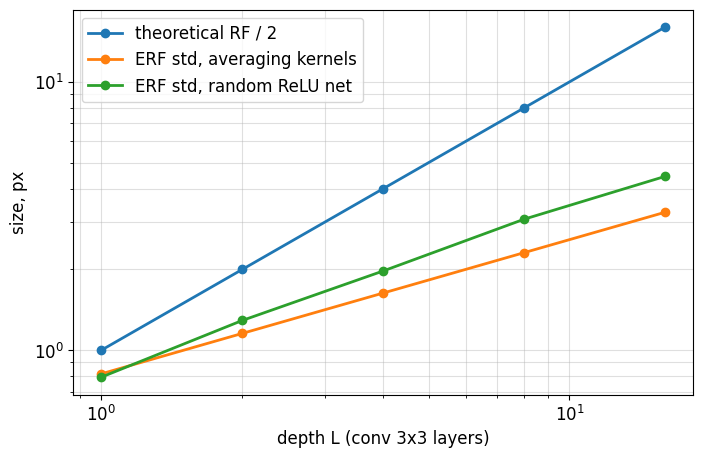

In [ ]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** На log-log графике теоретический RF растет линейно с глубиной $L$ (наклон 1, так как $r_L = 2L + 1$), тогда как эффективный RF (ERF std) растет как $\sqrt{L}$ (наклон 0.5). Это следует из Центральной Предельной Теоремы: карта градиента для стопки из $L$ усредняющих свёрток $3 \times 3$ — это распределение суммы $L$ независимых равномерных величин, дисперсия которой растет как $L \cdot \frac{2}{3}$, откуда $\sigma_{\text{ERF}} = \sqrt{2L/3}$. Следовательно, отношение ERF к теоретическому RF падает как $1/\sqrt{L}$ — с увеличением глубины центральные пиксели вносят всё больший вклад по сравнению с краями.

Сеть с ReLU ведет себя качественно похоже: её ERF также растет как $\sqrt{L}$ (наклон на log-log графике близок к 0.5). Однако абсолютные значения ERF для ReLU-сети выше, чем для усредняющей (4.44 против 3.27 при $L=16$). Это может быть связано с тем, что Kaiming-инициализация ($\mathcal{N}(0, 2/\text{fan\_in})$) дает бо́льшую дисперсию весов по сравнению с усредняющими ядрами ($1/k^2 = 1/9$), и градиент распространяется дальше. Кроме того, ReLU обнуляет примерно половину активаций, но оставшиеся пути имеют бо́льшие веса, что компенсирует "прореживание" и даже увеличивает эффективный радиус.


---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum

        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), unbiased=False)

            x_norm = (x - mean.view(1, -1, 1, 1)) / torch.sqrt(var.view(1, -1, 1, 1) + self.eps)
            out = self.weight.view(1, -1, 1, 1) * x_norm + self.bias.view(1, -1, 1, 1)

            n = x.shape[0] * x.shape[2] * x.shape[3]
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mean
            self.running_var = (1 - self.momentum) * self.running_var + self.momentum * var * n / (n - 1)
            self.num_batches_tracked += 1
        else:
            x_norm = (x - self.running_mean.view(1, -1, 1, 1)) / torch.sqrt(self.running_var.view(1, -1, 1, 1) + self.eps)
            out = self.weight.view(1, -1, 1, 1) * x_norm + self.bias.view(1, -1, 1, 1)

        return out

In [ ]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В нормировку текущего батча идёт смещённая оценка дисперсии (`unbiased=False`), потому что мы нормируем именно этот конкретный батч, и его собственная дисперсия является наиболее точной характеристикой разброса данных внутри него.

В `running_var` (которая используется на инференсе для всего датасета) идёт несмещённая оценка (`var * n / (n - 1)`), чтобы компенсировать систематическое занижение дисперсии при оценке по выборке и сделать статистику более репрезентативной для генеральной совокупности. Разница между ними определяется множителем $n / (n - 1)$:

1. При $B = 4$ и карте $5 \times 5$: $n = 4 \times 5 \times 5 = 100$. Множитель равен $100 / 99 \approx 1.01$ (разница ~1%).

2. При $B = 2$ и карте $1 \times 1$: $n = 2 \times 1 \times 1 = 2$. Множитель равен $2 / 1 = 2.0$ (разница 100%, смещённая оценка занижает дисперсию в два раза).

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** Пусть выход свёртки $y = W x + b_c$ (где $b_c$ — bias свёртки, может быть нулевым). BatchNorm применяет аффинное преобразование: $z = \gamma \frac{y - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta$. Теперь подставим $y$ в формулу BN:

$$z = \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} (W x + b_c - \mu) + \beta = \left( \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} W \right) x + \left( \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} (b_c - \mu) + \beta \right)$$

Значит, новые веса и bias для эквивалентной свёртки:

$$W' = \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} W, \qquad b' = \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} (b_c - \mu) + \beta$$

Здесь $\gamma, \beta, \mu, \sigma^2$ — параметры и буферы BatchNorm (поканальные векторы), а деление и умножение на них происходит поэлементно по каналу (broadcasting по осям $C_{in}, kH, kW$).



In [ ]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    gamma = bn.weight
    beta = bn.bias
    mu = bn.running_mean
    var = bn.running_var
    eps = bn.eps

    scale = gamma / torch.sqrt(var + eps)
    w = conv.weight
    b = conv.bias if conv.bias is not None else torch.zeros_like(mu)
    w_fused = w * scale.view(-1, 1, 1, 1)
    b_fused = scale * (b - mu) + beta

    fused_conv = nn.Conv2d(
        in_channels=conv.in_channels,
        out_channels=conv.out_channels,
        kernel_size=conv.kernel_size,
        stride=conv.stride,
        padding=conv.padding,
        dilation=conv.dilation,
        groups=conv.groups,
        bias=True,
        padding_mode=conv.padding_mode,
        dtype=conv.weight.dtype,
        device=conv.weight.device
    )

    fused_conv.weight.data.copy_(w_fused)
    fused_conv.bias.data.copy_(b_fused)

    return fused_conv


def fuse_sequential(seq):
    modules = []
    layer_list = list(seq.children())
    i = 0

    while i < len(layer_list):
        if (i + 1 < len(layer_list) and
            isinstance(layer_list[i], nn.Conv2d) and
            isinstance(layer_list[i+1], nn.BatchNorm2d)):

            fused = fuse_conv_bn(layer_list[i], layer_list[i+1])
            modules.append(fused)
            i += 2
        else:
            modules.append(copy.deepcopy(layer_list[i]))
            i += 1

    return nn.Sequential(*modules)

In [ ]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [ ]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [ ]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 136.2 ms   fused: 153.3 ms   speedup 0.89x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** Слияние корректно только в `eval()`, потому что в режиме обучения (`train()`) BatchNorm вычисляет среднее и дисперсию по текущему батчу, которые меняются от шага к шагу, а статическая свёртка не может это воспроизвести. В режиме инференса BN использует фиксированные `running_mean`, `running_var` и превращается в обычное поканальное аффинное преобразование, которое алгебраически поглощается предыдущей свёрткой.

1.  Что даёт слияние: исчезает отдельный проход по памяти (чтение и запись промежуточного тензора между Conv и BN), а на GPU ещё и запуск отдельного ядра BN. Число параметров и FLOPs свёртки не меняются.

2.  От чего зависит выигрыш: от того, насколько BN в сети memory-bound по сравнению со свёрткой. Выигрыш заметен, когда карты признаков большие, а вычисления свёртки дёшевы (малое число каналов, depthwise-свёртки, маленький батч на GPU). Когда время почти целиком уходит на сами свёртки, выигрыш мал.

В нашем замере ускорения нет: Conv + BN 136.2 мс, fused 153.3 мс, то есть 0.89×. Модель `vgg` в этой ячейке не переносилась на `device`, то есть замер шёл на CPU, где при 64 каналах и батче 64 доминирует сама свёртка, а стоимость поэлементного BN мала. Разница в 12% на одном замере (`min` из 5 повторов) не отличается от шума измерения, поэтому вывод «слияние замедляет» делать нельзя; можно сказать только, что на этой конфигурации выигрыша не видно.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:

$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big]
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Для слоя $h = Wz$ дисперсия выхода равна $\text{Var}(h) = n \cdot v \cdot \mathbb{E}[z^2]$.

1. Для ReLU: если $h^{\text{prev}}$ симметрично относительно нуля, то $\text{ReLU}$ обнуляет половину значений, и $\mathbb{E}[z^2] = \frac{1}{2} \text{Var}(h^{\text{prev}})$. Чтобы дисперсия не менялась ($\text{Var}(h) = \text{Var}(h^{\text{prev}})$), нужно $n \cdot v \cdot \frac{1}{2} = 1$, откуда **$v = \frac{2}{n}$** (инициализация Kaiming/He).

2. Для tanh в линейном режиме: $z \approx h^{\text{prev}}$, поэтому $\mathbb{E}[z^2] = \text{Var}(h^{\text{prev}})$. Условие сохранения дисперсии: $n \cdot v = 1$, откуда **$v = \frac{1}{n}$** (инициализация Xavier/Glorot).

3. Для инициализации по умолчанию $\mathcal{U}(-1/\sqrt{n}, 1/\sqrt{n})$ дисперсия весов равна $v = \frac{1}{3n}$. При использовании ReLU дисперсия активаций за слой меняется в $n \cdot \frac{1}{3n} \cdot \frac{1}{2} = \frac{1}{6}$ раз. Следовательно, стандартное отклонение за слой меняется в $\frac{1}{\sqrt{6}} \approx 0.408$ раз (то есть быстро затухает).

In [ ]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)

    stds = []
    x = torch.randn(n, width)

    for _ in range(depth):
        w = torch.empty(width, width)
        init(w)

        h = x @ w.T
        x = act(h)

        stds.append(x.std().item())

    return stds


In [ ]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

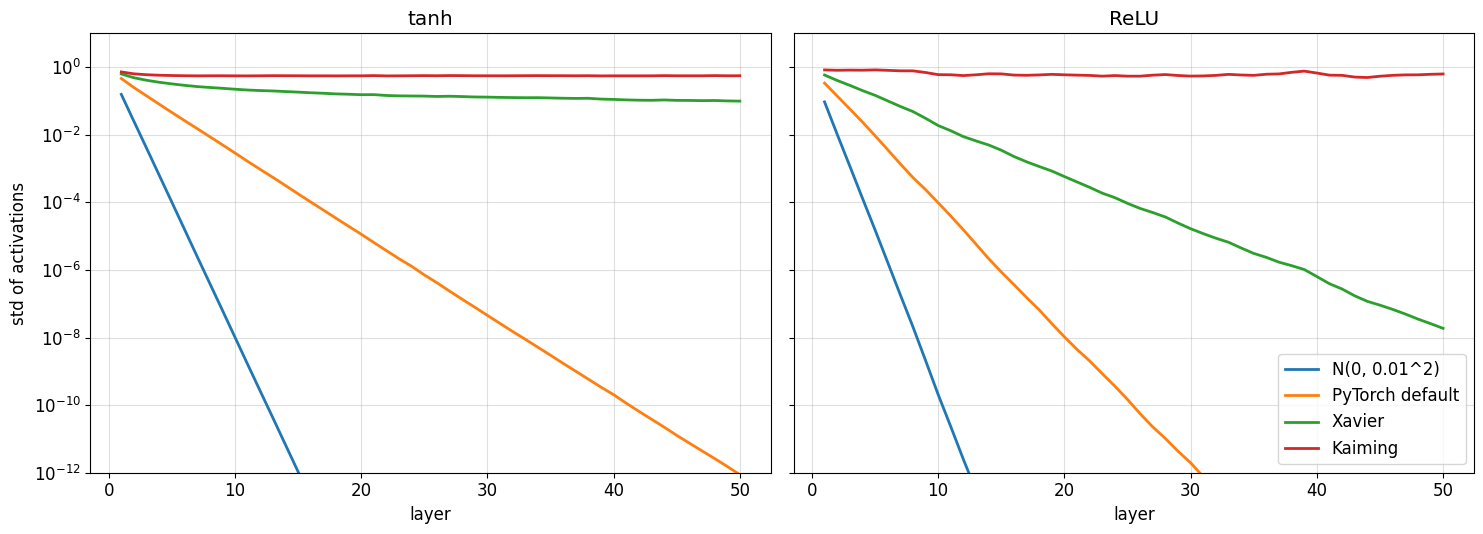

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Масштаб активаций на 50 слоях сохраняют пары (Kaiming, ReLU) и (Xavier, tanh), так как их дисперсия весов подобрана в точности под математическое ожидание квадрата выхода соответствующей функции активации. Сети с инициализацией PyTorch по умолчанию (и даже с затухающим масштабом активаций) всё равно успешно обучаются, особенно ResNet, по двум главным причинам:

1. Skip-connections (остаточные связи): в ResNet градиент и сигнал проходят напрямую через тождественное отображение (shortcut), минуя последовательное умножение на матрицы весов. Это предотвращает исчезновение градиента.

2. Batch Normalization: слой нормализации принудительно возвращает активациям нулевое среднее и единичную дисперсию на каждом шаге, полностью компенсируя любые проблемы с масштабом, вызванные инициализацией.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [ ]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']

            lr = group['lr']
            eps = group['eps']
            weight_decay = group['weight_decay']
            bias_correction = group['bias_correction']

            for p in group['params']:
                if p.grad is None:
                    continue

                g = p.grad

                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)

                state['step'] += 1
                t = state['step']
                m = state['m']
                v = state['v']

                if weight_decay != 0:
                    p.mul_(1 - lr * weight_decay)

                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)

                if bias_correction:
                    m_hat = m / (1 - beta1 ** t)
                    v_hat = v / (1 - beta2 ** t)
                else:
                    m_hat = m
                    v_hat = v

                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)

In [ ]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [ ]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


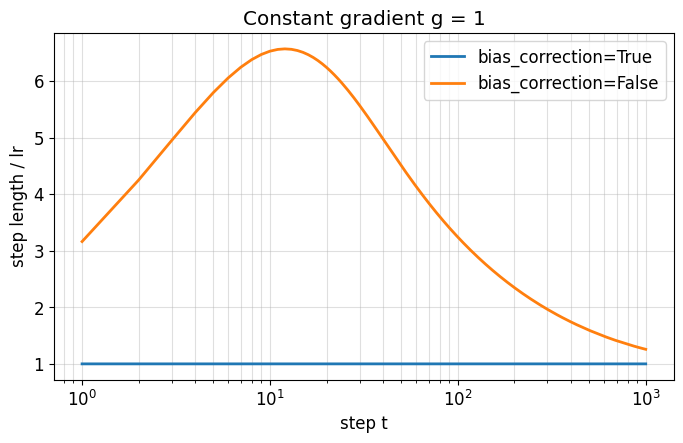

In [ ]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** При постоянном градиенте $g_t \equiv 1$ и $m_0 = v_0 = 0$:

$$m_t = (1-\beta_1)\sum_{i=1}^t \beta_1^{t-i} = 1 - \beta_1^t, \qquad v_t = 1 - \beta_2^t.$$

Без bias correction длина шага (при $\varepsilon \ll \sqrt{v_t}$):

$$\Delta_t \approx \eta\,\frac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t}}.$$

При $\beta_1 = 0.9,\ \beta_2 = 0.999$:

1.  При малых $t$: $m_t \approx (1-\beta_1)t$, $v_t \approx (1-\beta_2)t$, откуда $\Delta_t \approx \eta\,\frac{1-\beta_1}{\sqrt{1-\beta_2}}\sqrt{t} \approx 3.16\,\eta\sqrt t$. При $t=1$ шаг уже равен $3.16\,\eta$.

2.  Оценка $m_t$ «прогревается» быстро (постоянная времени $\approx 10$ шагов), а $v_t$ медленно ($\approx 1000$ шагов), поэтому знаменатель ещё заметно меньше своего предельного значения, когда числитель уже близок к 1. Шаг достигает максимума при $t = 12$ и равен $6.57\,\eta$ (в выводе ячейки: $t=10$: 6.53, максимум 6.57 при $t=12$).

3.  Затем $v_t$ догоняет, шаг убывает и стремится к $\eta$ (при $t=100$ он ещё 3.24, при $t=1000$ — 1.26).

Опасность в начале обучения: без bias correction первые десятки шагов в несколько раз **длиннее** номинального $\eta$ (до $6.6\eta$), потому что $v_t$ занижена из-за нулевой инициализации. Это эквивалентно кратковременному увеличению learning rate ровно тогда, когда оценки градиента самые шумные и веса ещё далеки от хорошей области, и может привести к расходимости или к плохому участку ландшафта. Bias correction делит $m_t$ и $v_t$ на $1-\beta^t$ и возвращает шаг к $\eta$ с первого шага (в выводе: ровно 1.00 при постоянном градиенте).

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    if step >= total_steps:
        return min_ratio

    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * step / total_steps)) / 2

In [ ]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

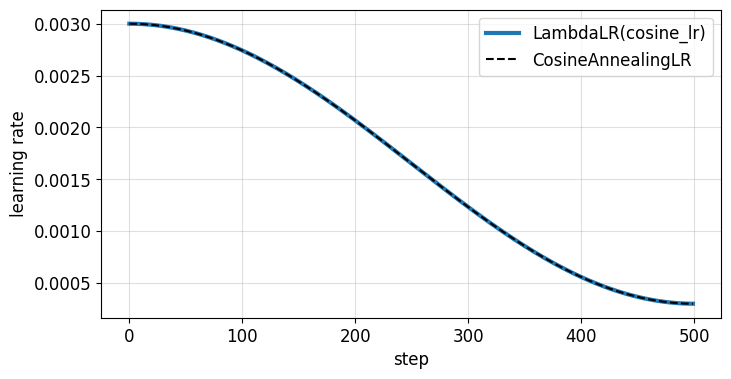

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивные оптимизаторы (Adam, AdamW) нормируют шаг покомпонентно — делят каждую компоненту градиента на оценку её RMS, — но не меняют общий масштаб шага. Если `lr` константен, то и длина шага в среднем остаётся фиксированной.

Стохастический градиент содержит шум от выбора мини-батча: $g_t = \nabla L(\theta_t) + \xi_t$, где $\mathbb{E}[\xi_t] = 0$, но $\text{Var}(\xi_t) > 0$. В окрестности минимума истинный градиент $\nabla L \approx 0$, и шаг определяется почти целиком шумом: $\Delta\theta \approx \eta \cdot \xi / \sqrt{v}$. При постоянном $\eta$ модель не сходится, а осциллирует вокруг минимума с амплитудой, пропорциональной $\eta$. Это ухудшает и финальное значение loss, и обобщающую способность (модель "не settles" в плоском минимуме).

Cosine-расписание плавно уменьшает $\eta$ до нуля, что позволяет шуму затухнуть и модели точнее сойтись к минимуму. Кроме того, уменьшение LR в конце обучения эмпирически помогает найти более *плоский* минимум (flat minimum), что улучшает generalization — модель становится менее чувствительной к малым возмущениям параметров.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [ ]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [24:52<00:00, 114kB/s]


(torch.Size([10000, 3, 32, 32]),
 torch.Size([2000, 3, 32, 32]),
 tensor([0.4935, 0.4834, 0.4472], device='cuda:0'),
 tensor([0.2476, 0.2446, 0.2626], device='cuda:0'))

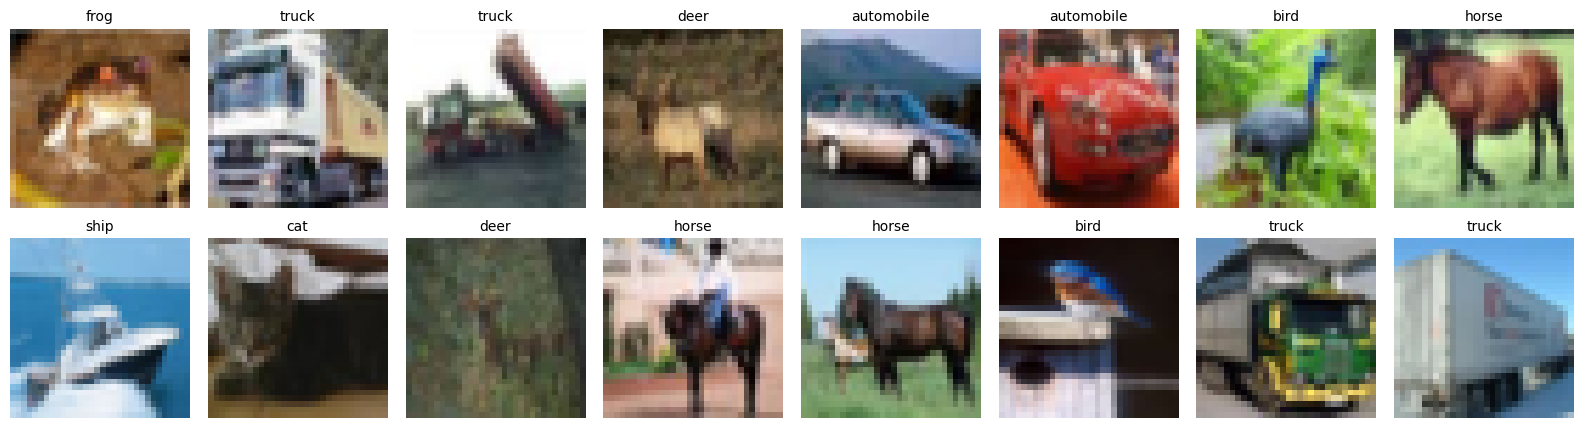

In [ ]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [ ]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )
    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                                              nn.BatchNorm2d(c_out))
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        h = F.relu(self.bn1(self.conv1(x)))
        h = self.bn2(self.conv2(h))
        if self.residual:
            h = h + self.shortcut(x)
        return F.relu(h)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, c_in = [], widths[0]
        for stage, width in enumerate(widths):
            for i in range(n):
                stride = 2 if (stage > 0 and i == 0) else 1
                blocks.append(Block(c_in, width, stride, residual, separable))
                c_in = width
        self.body = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(widths[-1], n_classes))

    def forward(self, x):
        return self.head(self.body(self.stem(x)))

In [ ]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [ ]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    optimizer = MyAdamW([dict(params=decay, weight_decay=weight_decay),
                         dict(params=no_decay, weight_decay=0.0)], lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps, 0.0))

    for epoch in range(epochs):
        model.train()
        loss_sum = torch.zeros((), device=device)
        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * len(y)
        history['train_loss'].append(loss_sum.item() / len(X_train))
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))

        if log:
            print(f'epoch {epoch + 1:>2}/{epochs}  loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  lr {scheduler.get_last_lr()[0]:.2e}  '
                  f'{time.time() - start:.0f}s')

    return history

In [ ]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch  1/3  loss 1.8091  test acc 0.3185  lr 2.25e-03  6s
epoch  2/3  loss 1.4816  test acc 0.4320  lr 7.50e-04  10s
epoch  3/3  loss 1.2916  test acc 0.5270  lr 0.00e+00  14s


{'train acc': 0.5547999739646912, 'test acc': 0.5270000100135803}

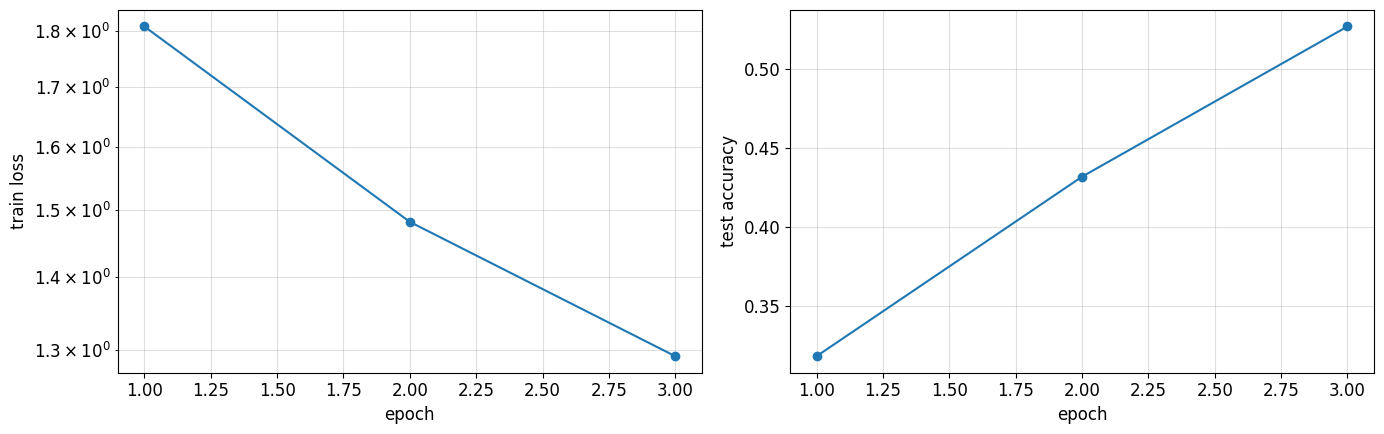

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В `FAST_MODE` (10 000 картинок train, 2000 test, 3 эпохи) в конце обучения train accuracy на первых 10 000 объектах равна 0.555, test accuracy — 0.527, то есть разрыв около 3 п.п. (стандартная ошибка test accuracy на 2000 объектах около 1 п.п.). Обе accuracy низкие и близки друг к другу: модель недообучена, переобучения нет.

На последних эпохах, когда learning rate по cosine идёт к нулю, train loss снижается монотонно (1.81 $\to$ 1.48 $\to$ 1.29), но снижение замедляется (шаги −0.33 и −0.19), а test accuracy продолжает расти (0.319 $\to$ 0.432 $\to$ 0.527) и признаков плато не показывает. Модель ещё далека от минимума, а бюджет в 3 эпохи слишком мал, чтобы был виден эффект затухания шума SGD при lr $\to$ 0 (выход test accuracy на плато при продолжающемся падении train loss).

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [ ]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [ ]:
ablation = {}

for name, cfg in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**cfg)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR, log=False)
    minutes = (time.perf_counter() - started) / 60
    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = dict(params=n_params(model), train_acc=train_acc, test_acc=hist['test_acc'][-1],
                          minutes=minutes, history=hist)

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

model                    params  train acc  test acc  minutes
plain-20                269,722     0.3610    0.3585      0.1
plain-56                853,018     0.2182    0.2370      0.4


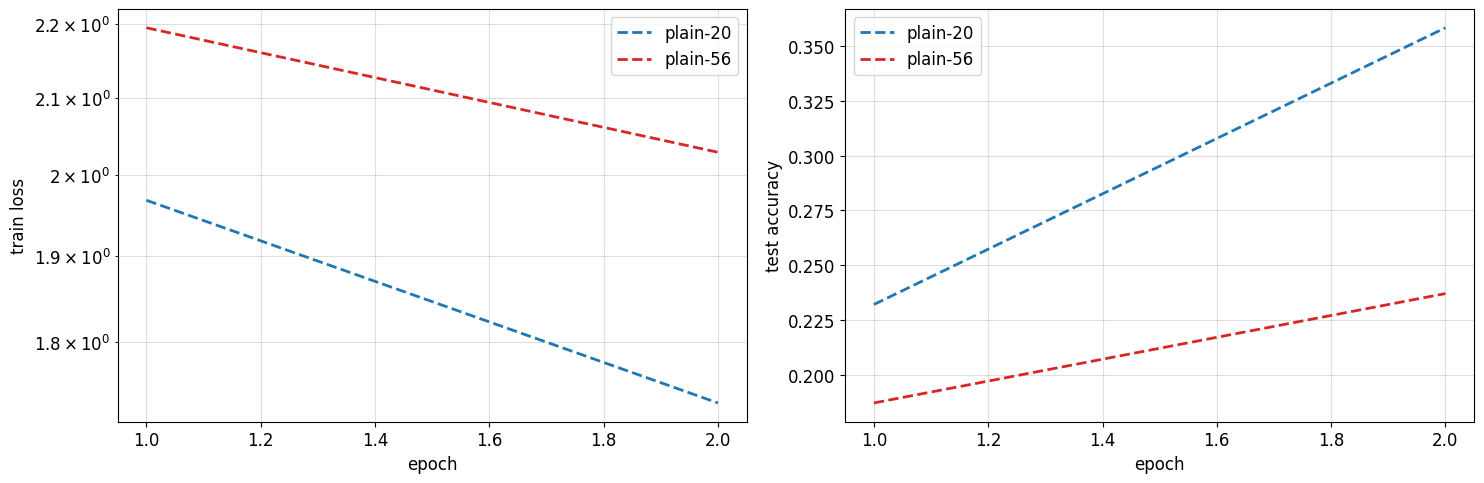

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Да, в нашем прогоне (`FAST_MODE`, 2 эпохи) plain-56 хуже plain-20 уже на train: train loss ~2.03 против ~1.73 на последней эпохе, train accuracy 0.218 против 0.361. Test accuracy: 0.237 против 0.359.

Что говорит об оптимизации, а не о переобучении:

1.  Более глубокая сеть хуже уже на обучающих данных (при переобучении train был бы лучше, а не хуже).

2.  Разрыв между train и test accuracy минимален: у plain-20 +0.3 п.п. (0.361 против 0.359), у plain-56 test даже выше train на 1.9 п.п. (0.237 против 0.218). Переобучения нет у обеих.

3.  Обе модели далеки от насыщения (22–36% при случайном уровне 10%): это начало обучения, и plain-56 просто стартует медленнее.

Ограничения: бюджет 2 эпохи (cosine до нуля за 2 эпохи), один seed, 10 000 объектов train, test на 2000 объектах (стандартная ошибка около 1 п.п.). Медленный старт глубокой plain-сети — ещё не доказательство degradation в смысле He et al., где речь о сходимости к худшему train error при полном обучении.

Контрольный эксперимент: обучить ResNet-56 (`residual=True`) с тем же протоколом (`LR`, `ABL_EPOCHS`, `set_seed(0)`). Если причина в оптимизации, то ResNet-56 должна показать train loss не хуже, чем ResNet-20 и plain-20, и заметно лучше plain-56; если ResNet-56 окажется так же плоха, как plain-56, объяснение через трудности оптимизации без skip-связей не подтверждается.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [ ]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 213kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.3MB/s]


(torch.Size([12000, 1, 28, 28]), torch.Size([256, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [ ]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [ ]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.83984375, 'FGSM, eps=0.1': 0.328125, 'PGD-20, eps=0.1': 0.23046875}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [ ]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()

    for _ in range(steps):
        x_adv.requires_grad_(True)

        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)

        g_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        delta = x_adv.detach() + alpha * grad / g_norm - x
        d_norm = delta.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        delta = delta * torch.clamp(eps / d_norm, max=1.0)
        x_adv = (x + delta).clamp(0, 1).detach()

    return x_adv

In [ ]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.762; маленькое падение требует диагностики.


(0.83984375, 0.078125)

In [ ]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.83984375,
  0.5: 0.6953125,
  1.0: 0.46875,
  1.5: 0.2734375,
  2.0: 0.078125,
  3.0: 0.00390625,
  4.0: 0.0},
 0.23046875)

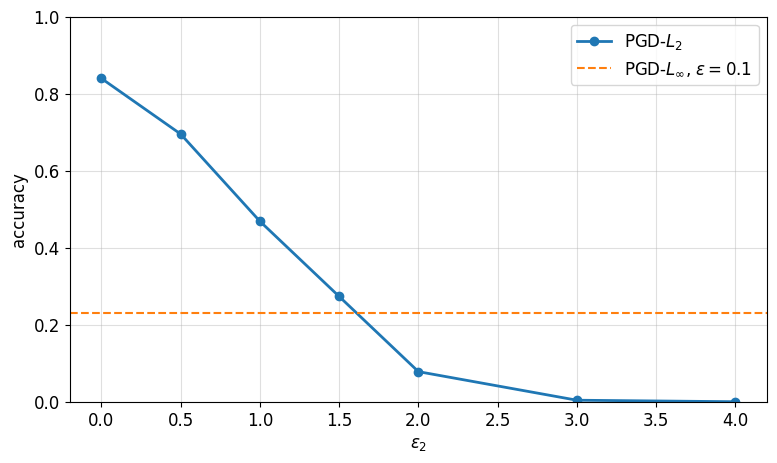

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.043


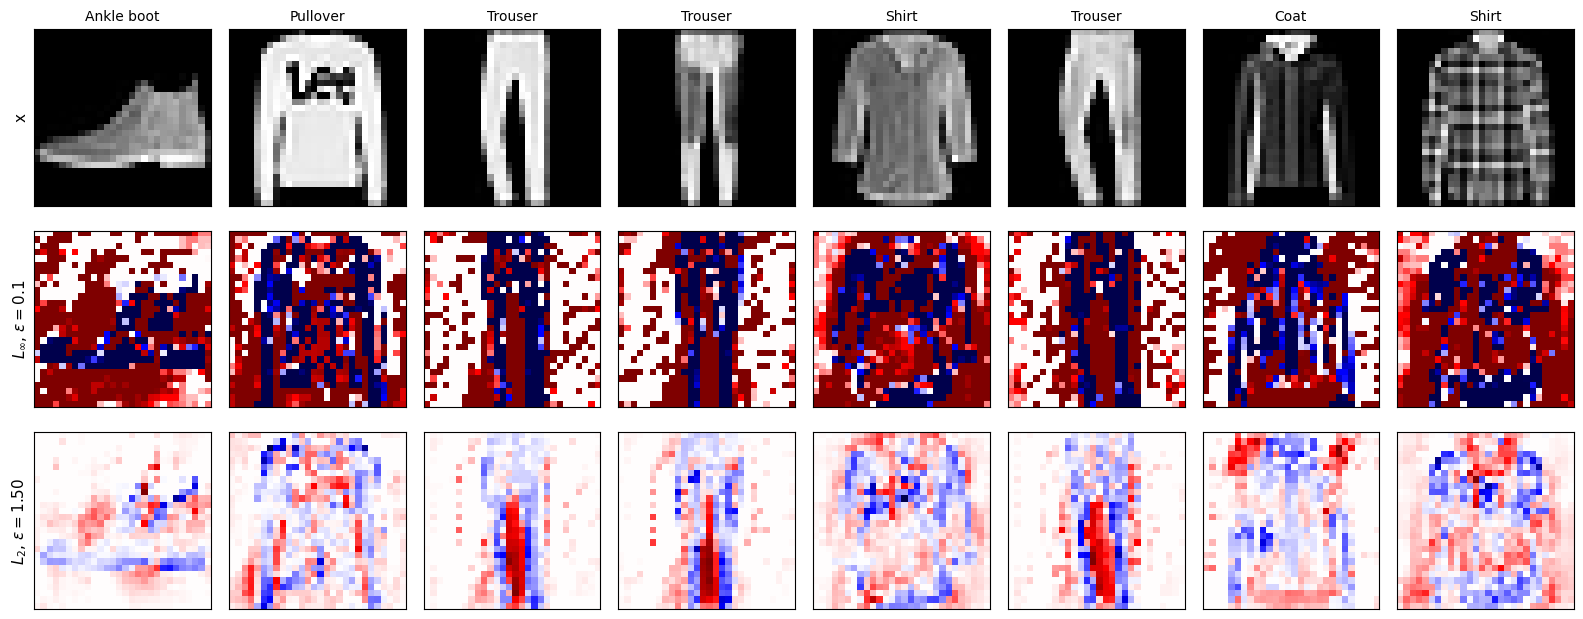

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.194
$L_2$, $\varepsilon=1.50$    L_inf = 0.319   L_2 = 1.495


In [ ]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближайшая точка сетки: $\varepsilon_2 = 1.5$ даёт accuracy $\approx 0.27$, тогда как $L_\infty$-атака с $\varepsilon = 0.1$ даёт $\approx 0.23$. Остаточный разрыв составляет $\approx 0.04$ (4 процентных пункта). Это означает, что $L_2$-шар радиуса 1.5 и $L_\infty$-шар радиуса 0.1 имеют сопоставимую, но не идентичную силу атаки.

$L_2$-норма $L_\infty$-возмущения: если все 784 пикселя изменены на $\pm 0.1$, то максимум равен $\sqrt{784 \cdot 0.1^2} \approx 2.8$. Фактическая средняя $L_2$-норма из вывода под рисунком — **2.19**, примерно 78% от максимума: часть пикселей упирается в границы $[0, 1]$ и может сдвигаться только в одну сторону. Для сравнения: $L_2$-возмущение при $\varepsilon_2 = 1.5$ имеет среднюю $L_2$-норму 1.50, но $L_\infty$-норму 0.32 (втрое больше 0.1), то есть похожую accuracy оно даёт при меньшей $L_2$-норме за счёт концентрации на небольшом числе пикселей, а $L_\infty$-атака рассредоточивает бюджет по всему изображению.

Где сосредоточено $L_2$-возмущение: На картах видно, что $L_2$-возмущение (нижний ряд) сосредоточено на границах объектов и ключевых признаках: контуры ботинка, воротник свитера, пояс брюк, пуговицы рубашки. Фон и однородные области почти не затронуты. В отличие от этого, $L_\infty$-возмущение (средний ряд) распределено равномерно по всему изображению — каждый пиксель изменён на $\pm 0.1$, создавая высокочастотный шум.

Связь с нормированным градиентом: $L_2$-PGD на каждом шаге делает обновление $\delta \leftarrow \delta + \alpha \cdot g / \|g\|_2$, где $g = \nabla_x L$. Нормировка на $L_2$-норму градиента означает, что направление шага совпадает с направлением градиента, но величина шага фиксирована. Пиксели с большим абсолютным градиентом (границы, текстуры, где loss чувствителен к изменениям) получают бо́льшие возмущения в абсолютном выражении, так как градиент там больше. Фон с малым градиентом почти не меняется. Это делает $L_2$-атаку более структурированной и интерпретируемой — она меняет именно те пиксели, которые важны для классификации.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)

        for _ in range(steps):
            x_adv.requires_grad_(True)

            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)

            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)

        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        alpha = 2.5 * eps / steps
        hits = torch.zeros(n_classes, n_classes)
        counts = torch.bincount(y.cpu(), minlength=n_classes).float()

        for t in range(n_classes):
            idx = (y != t).nonzero().squeeze(1)

            for start in range(0, len(idx), 128):
                b = idx[start:start + 128]
                xb, yb = x[b], y[b]
                x_adv = pgd_targeted(model, xb, torch.full_like(yb, t), eps, alpha, steps)

                with torch.no_grad():
                    hit = model(x_adv).argmax(dim=1) == t

                hits[:, t] += torch.bincount(yb[hit].cpu(), minlength=n_classes).float()

        S = hits / counts.clamp_min(1).unsqueeze(1)
        S[counts == 0] = float('nan')
        S.fill_diagonal_(float('nan'))

        return S

In [ ]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.238; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.84 0.   0.   0.04 0.   0.   0.12 0.   0.   0.  ]
 [0.   0.97 0.   0.03 0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.65 0.05 0.19 0.   0.11 0.   0.   0.  ]
 [0.   0.   0.   1.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.11 0.04 0.74 0.   0.11 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.95 0.   0.05 0.   0.  ]
 [0.   0.   0.14 0.09 0.18 0.   0.55 0.   0.05 0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.93 0.04 0.04]
 [0.   0.   0.   0.   0.   0.   0.04 0.   0.96 0.  ]
 [0.   0.   0.   0.   0.   0.04 0.   0.04 0.   0.92]]


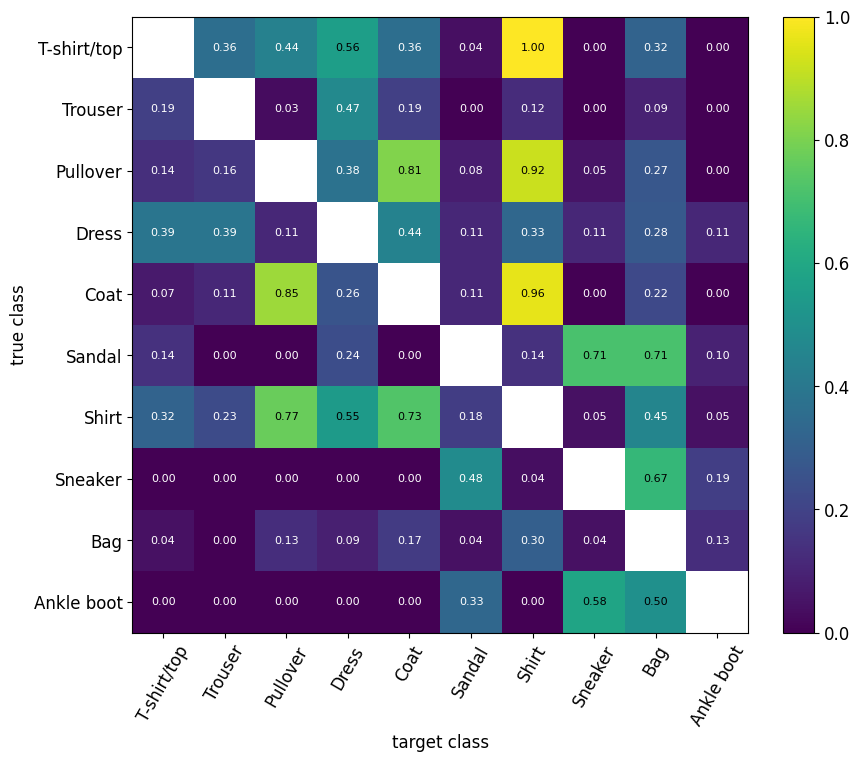

In [ ]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Легче всего атакуются пары визуально похожих классов одежды:

1.  T-shirt/top в Shirt: 1.00, Coat в Shirt: 0.96, Pullover в Shirt: 0.92 — все три верхних класса легко превращаются в Shirt.

2.  Coat в Pullover: 0.85, Shirt в Pullover: 0.77 — взаимные переходы между верхней одеждой.

3.  Sandal в Sneaker: 0.71, Sandal в Bag: 0.71, Sneaker в Bag: 0.67 — обувь и сумки.

Труднее всего атаковать пары из разных семантических категорий:

1.  Trouser в Sneaker/Shirt/Coat: 0.00 — брюки почти невозможно превратить в обувь или верх.

2.  Pullover в Sneaker/Ankle boot: 0.00 — свитер не становится обувью.

3.  Coat в Sneaker/Ankle boot: 0.00 — пальто не превращается в обувь.

4.  Dress в Sneaker: 0.00 — платье не становится кроссовком.

Матрица не симметрична: есть яркие примеры асимметрии:

1.  T-shirt/top в Shirt: 1.00, но при этом Shirt в T-shirt/top: 0.32 (в 3 раза меньше).

2.  Coat в Shirt: 0.96, но Shirt в Coat: 0.73.

3.  Pullover в Shirt: 0.92, но Shirt в Pullover: 0.77.

Это означает, что атака в одном направлении требует меньшего возмущения, чем в обратном.

Связь с clean confusion matrix: пары, которые модель путает без атаки, действительно легче атаковать targeted-методом:

1.  В clean: Coat в Shirt (0.11) и Shirt в Coat (0.18) — взаимные ошибки. В targeted: Coat в Shirt (0.96) и Shirt в Coat (0.73) — обе высокие.

2.  В clean: Pullover в Coat (0.19) и Coat в Pullover (0.11). В targeted: Coat в Pullover (0.85) и Pullover в Coat (0.81) — обе высокие.

3.  Обувь: в clean confusion matrix Sneaker и Ankle boot почти не путаются (по 0.04 в обе стороны), так что связь targeted-успеха с clean-ошибками здесь слабее, чем у верхней одежды: близость классов по признакам в атаке не сводится к их частоте путаницы без атаки.

Объяснение: если decision boundary между классами $s$ и $t$ находится близко к примеру класса $s$, то малое возмущение пересекает границу в направлении $t$ (высокая успешность). Обратное направление может требовать большего шага, если граница дальше от класса $t$. Clean confusion matrix показывает, где границы уже близки к данным — именно эти пары и оказываются уязвимыми для targeted-атак.

Ограничение: в `FAST_MODE` в test всего 256 объектов, то есть около 25 на класс, поэтому значения в матрице $S$ и в clean confusion кратны примерно 0.04 и сильно шумят; различия в несколько сотых между парами нельзя считать надёжными.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** выполнялась ветка 5.2.

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [ ]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [ ]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])    

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X_eval, Y_eval = XF_test[:1000], YF_test[:1000]

    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps).detach()
            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        model.eval()
        history['clean'].append(attack_accuracy(model, X_eval, Y_eval))
        history['fgsm'].append(attack_accuracy(model, X_eval, Y_eval, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, X_eval, Y_eval, pgd, eps=eps))

        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  '
                  f'FGSM {history["fgsm"][-1]:.3f}  PGD-20 {history["pgd"][-1]:.3f}')

    model.eval()

    for p in model.parameters():
        p.grad = None

    return history

In [ ]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/2  clean 0.789  FGSM 0.613  PGD-20 0.562
epoch 2/2  clean 0.797  FGSM 0.645  PGD-20 0.613


In [ ]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.840   0.566   0.234   0.055   0.000   0.000
PGD-AT       0.797   0.723   0.609   0.457   0.211   0.004


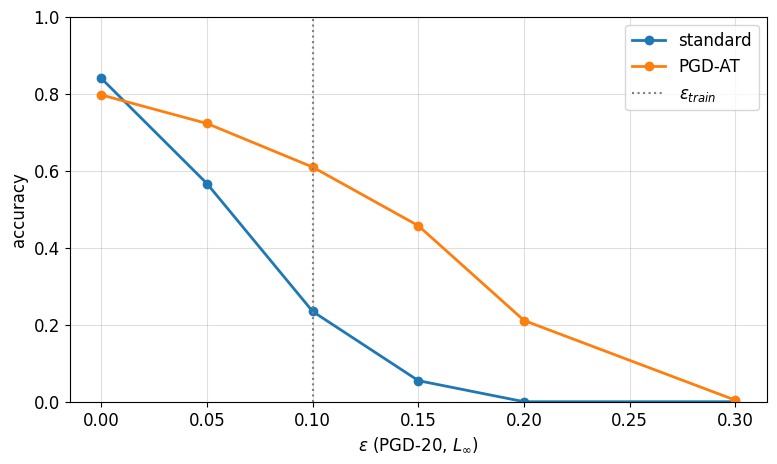

In [ ]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.**

Цена робастности в clean accuracy: PGD-AT модель показывает clean accuracy ≈ 0.80 против ≈ 0.84 у стандартной модели. Разрыв составляет ~4 процентных пункта. Это типичный trade-off: обучение на adversarial примерах смещает decision boundary, что ухудшает производительность на чистых данных, но делает модель устойчивой к атакам.

При $\varepsilon$ > $\varepsilon_{\text{train}}$ (0.1): обе модели продолжают терять accuracy, но PGD-AT сохраняет значительное преимущество. При $\varepsilon$ = 0.15: standard ≈ 0.05, PGD-AT ≈ 0.46. При $\varepsilon$ = 0.2: standard ≈ 0.0, PGD-AT ≈ 0.21. При $\varepsilon$ = 0.3 обе модели достигают ~0. Это показывает, что робастность, полученная при обучении с $\varepsilon$ = 0.1, частично переносится на бо́льшие радиусы, но не полностью — модель не может противостоять атакам, значительно превосходящим тренировочный бюджет.

Стоимость PGD-AT: при K шагах PGD каждый шаг требует 1 forward + 1 backward pass (для вычисления градиента по входу), плюс 1 forward + 1 backward для обновления весов после атаки. Итого: (K+1) forward + (K+1) backward на батч. Для PGD-7 это 8 forward + 8 backward, тогда как обычное обучение требует 1 forward + 1 backward. PGD-AT в 8 раз дороже по числу операций.

Ограничение: в `FAST_MODE` evaluation идёт на 256 объектах (стандартная ошибка accuracy около 2–3 п.п.), поэтому разрыв в 4 п.п. по clean accuracy (0.797 против 0.840) на границе шума, а разрывы по PGD accuracy (0.609 против 0.234 при $\varepsilon = 0.1$) от шума отличаются уверенно. Время обучения можно сопоставить через `RUN_TIMES` (учтите, что в PGD-AT добавлена ещё оценка clean/FGSM/PGD-20 после каждой эпохи).

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def sanity_checks(model, x, y, eps):
    model.eval()

    @torch.no_grad()
    def is_correct(inp, lab):
        return model(inp).argmax(dim=1) == lab

    def robust_accuracy(attack, restarts=1):
        alive_all = []
        for i in range(0, len(x), 128):
            xb, yb = x[i:i + 128], y[i:i + 128]
            alive = is_correct(xb, yb)
            for _ in range(restarts):
                alive = alive & is_correct(attack(xb, yb), yb)
            alive_all.append(alive)
        return torch.cat(alive_all).float().mean().item()

    return dict(
        fgsm=robust_accuracy(lambda xb, yb: fgsm_attack(model, xb, yb, eps)),
        pgd20=robust_accuracy(lambda xb, yb: pgd(model, xb, yb, eps, steps=20)),
        pgd100_x5=robust_accuracy(lambda xb, yb: pgd_attack(model, xb, yb, eps, alpha=2.5 * eps / 100, steps=100),
                                  restarts=5),
        eps_1=robust_accuracy(lambda xb, yb: pgd(model, xb, yb, 1.0, steps=20)),
    )

In [ ]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.328      0.250      0.242      0.000
PGD-AT                      0.633      0.602      0.602      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** Изменение accuracy при усилении атаки (в этом прогоне `N_SANITY = 128`):

1.  Standard: FGSM $\to$ PGD-20: 0.328 $\to$ 0.250 (−7.8 п.п.); PGD-20 $\to$ PGD-100×5: 0.250 $\to$ 0.242 (−0.8 п.п.); при $\varepsilon = 1$ — 0.000.

2.  PGD-AT: FGSM $\to$ PGD-20: 0.633 $\to$ 0.602 (−3.1 п.п.); PGD-100×5 не меняет результат (0.602); при $\varepsilon = 1$ — 0.000.

Наибольшее падение даёт переход от одношаговой атаки к итеративной. Усиление PGD-20 до PGD-100×5 почти ничего не добавляет, то есть 20 шагов достаточно в нашем протоколе. Порядок `fgsm ≥ pgd20 ≥ pgd100_x5 ≥ eps_1` выполняется для обеих моделей, подозрительных результатов нет. Разница 0.250 $\to$ 0.242 — это один объект из 128, она неотличима от шума (стандартная ошибка около 4 п.п.), но направлена в ожидаемую сторону.

Что проверил бы дополнительно: (1) больше объектов (на 128 объектах стандартная ошибка около 4 п.п.); (2) больше restarts и другой loss (например, margin loss вместо cross-entropy); (3) что PGD действительно доходит до границы шара (норма возмущений близка к $\varepsilon$) и что step size $2.5\varepsilon/\text{steps}$ не слишком мал; (4) что accuracy монотонно падает по сетке $\varepsilon$ и достигает нуля при большом $\varepsilon$.

Модель с высокой FGSM accuracy и почти нулевой PGD accuracy все перечисленные проверки пройти может: эти проверки требуют лишь монотонного убывания и низкой accuracy при $\varepsilon = 1$, они не требуют высокой PGD accuracy. Но тогда сказать о её robustness можно только одно: робастности нет, потому что итеративная атака её ломает. Высокая FGSM accuracy при этом показывает, что модель нелинейна в $\varepsilon$-шаре и одношаговая линеаризация её не находит (типичный признак catastrophic overfitting при обучении на FGSM). Это не gradient masking против PGD, так как PGD как раз работает. Если же и PGD-атаки показывают завышенную accuracy, а при большом $\varepsilon$ она не падает до нуля, это уже тревожный сигнал маскирования градиентов. В любом случае прохождение sanity checks не сертифицирует robustness (Athalye et al., 2018).

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def input_gradient(model, x, y):
    model.eval()
    out = []

    for i in range(len(x)):
        xi = x[i:i + 1].detach().clone().requires_grad_(True)

        with torch.enable_grad():
            z_y = model(xi)[0, y[i]]
            grad, = torch.autograd.grad(z_y, xi)

        out.append(grad.abs().detach())

    return torch.cat(out)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [ ]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.500


{'standard': 0.4187307357788086, 'PGD-AT': 0.240787535905838}

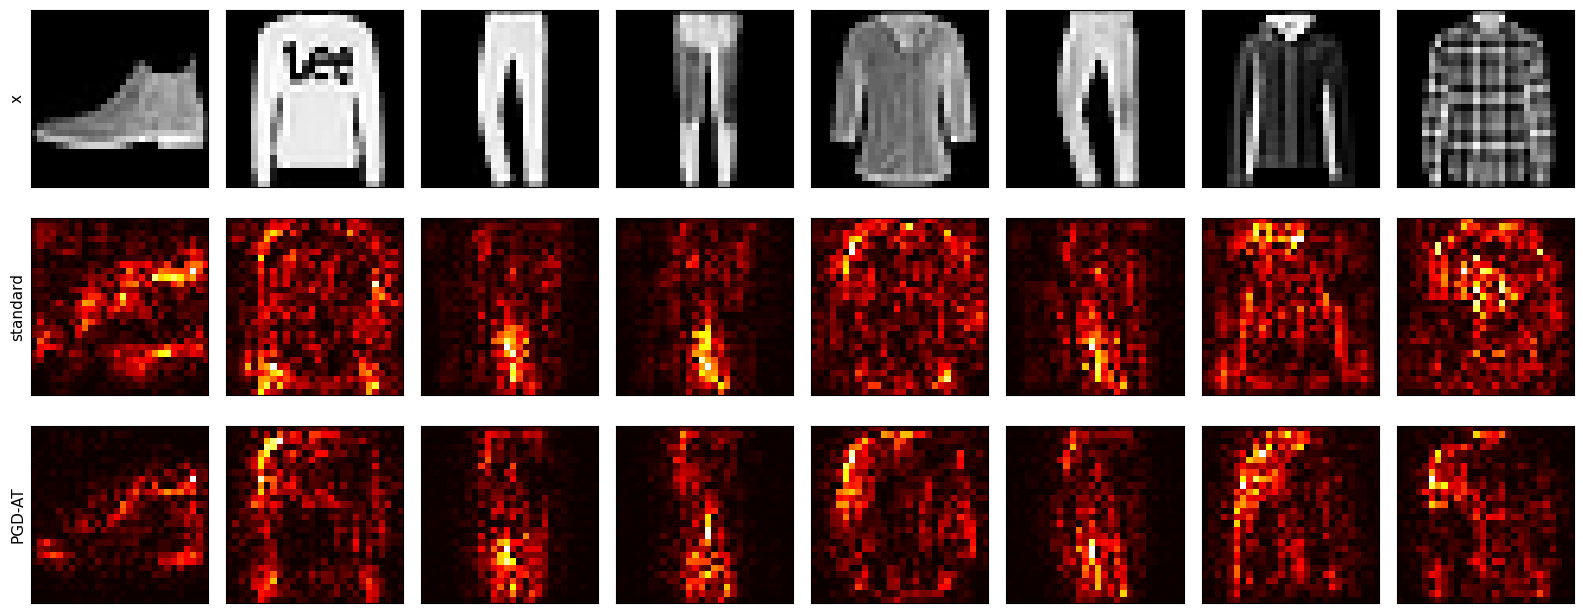

In [ ]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** Доля массы градиента $|\nabla_x z_y|$ на фоне (пиксели с $x = 0$; их доля на изображениях 0.500): у стандартной модели 0.419, у PGD-AT 0.241. У стандартной модели масса градиента распределена почти пропорционально площади фона (0.42 при площади 0.50), то есть она мало привязана к объекту. У PGD-AT фоновая доля почти вдвое меньше, и градиент заметно сильнее сосредоточен на самом объекте (на картах это видно как более локализованные и менее шумные пятна).

Это согласуется с различием PGD accuracy в нашем эксперименте: 0.609 у PGD-AT против 0.234 у стандартной модели при $\varepsilon = 0.1$. Но согласованность — наблюдение на одной паре моделей, одном seed и 256 объектах (в `FAST_MODE`), а не доказательство причинной связи: доля фона сама по себе не измеряет robustness.

Одной красивой saliency-карты недостаточно для вывода о robustness: она описывает локальный линейный отклик логита в одной точке, а не худший случай в $\varepsilon$-шаре; она считается по логиту верного класса, а не по loss, который атакует PGD; и её вид может определяться сглаживанием или масштабом логитов (в том числе маскированием градиентов), а не реальной устойчивостью. Поэтому вывод нужно опирать на атаки (PGD с restarts, раздел 6.2), а карты использовать как дополнительную иллюстрацию.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [ ]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        # ваш код
        raise NotImplementedError


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [ ]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [ ]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

In [ ]:
if '7.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.**

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [ ]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        # ваш код
        raise NotImplementedError

In [ ]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.**

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [ ]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        # ваш код
        raise NotImplementedError


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    # ваш код
                    raise NotImplementedError

In [ ]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [ ]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    # ваш код
    raise NotImplementedError
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

In [ ]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.**

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [ ]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

In [ ]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.**

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

In [ ]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [ ]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.**